In [1]:
!pip install opencv-python-headless scikit-image scikit-learn scipy pandas -q

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request
import pandas as pd

from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans
from scipy.fftpack import dct, idct

# Create folder for images
os.makedirs('/content/images', exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


Problem 1: Comparative Edge Detection on Natural Images


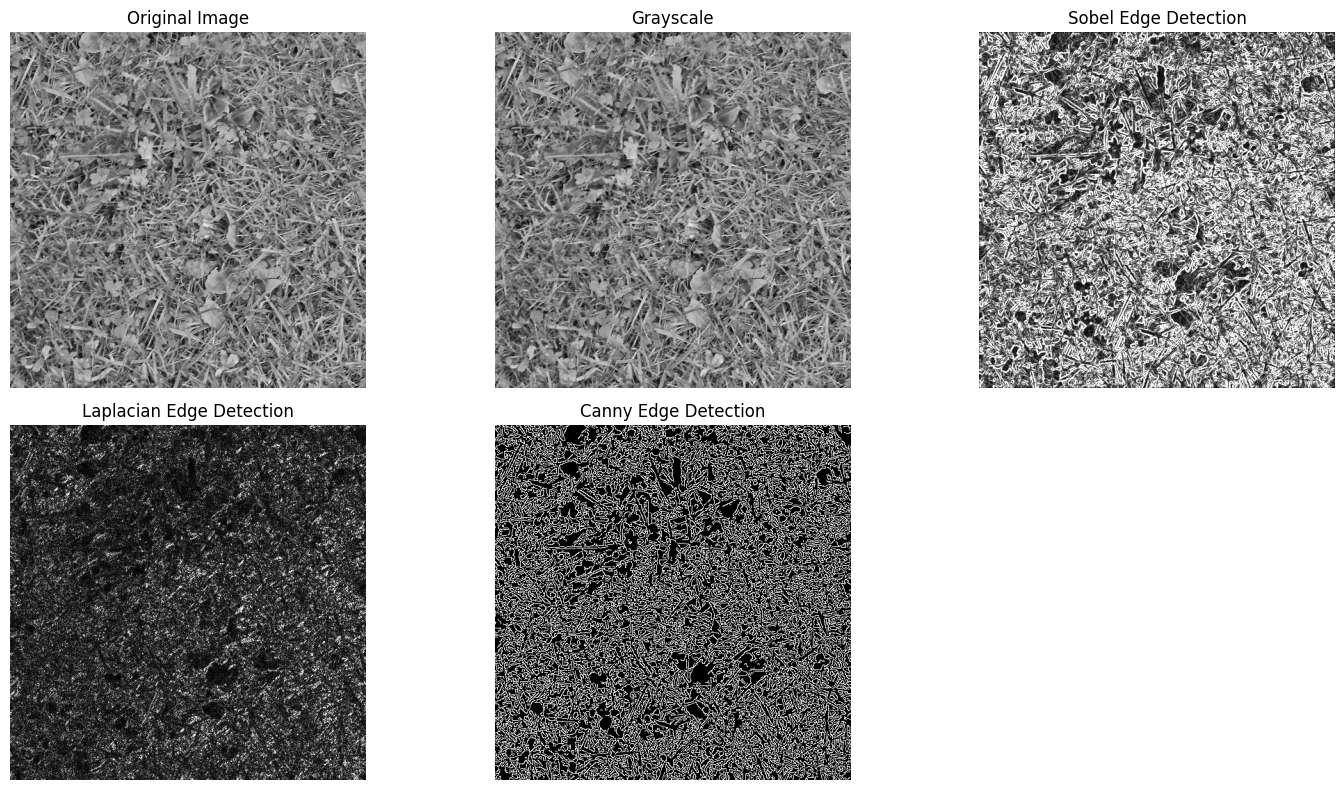

In [3]:
from skimage import data
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load natural grayscale image
image = data.grass()

# Use image directly as grayscale
gray = image.copy()

# Apply Sobel edge detection
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = cv2.convertScaleAbs(sobel)

# Apply Laplacian edge detection
laplacian = cv2.Laplacian(gray, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)

# Apply Canny edge detection
canny = cv2.Canny(gray, 100, 200)

# Display results
images = [image, gray, sobel, laplacian, canny]

titles = [
    "Original Image",
    "Grayscale",
    "Sobel Edge Detection",
    "Laplacian Edge Detection",
    "Canny Edge Detection"
]

plt.figure(figsize=(15, 8))

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

Problem 2: Noise Sensitivity Experiment

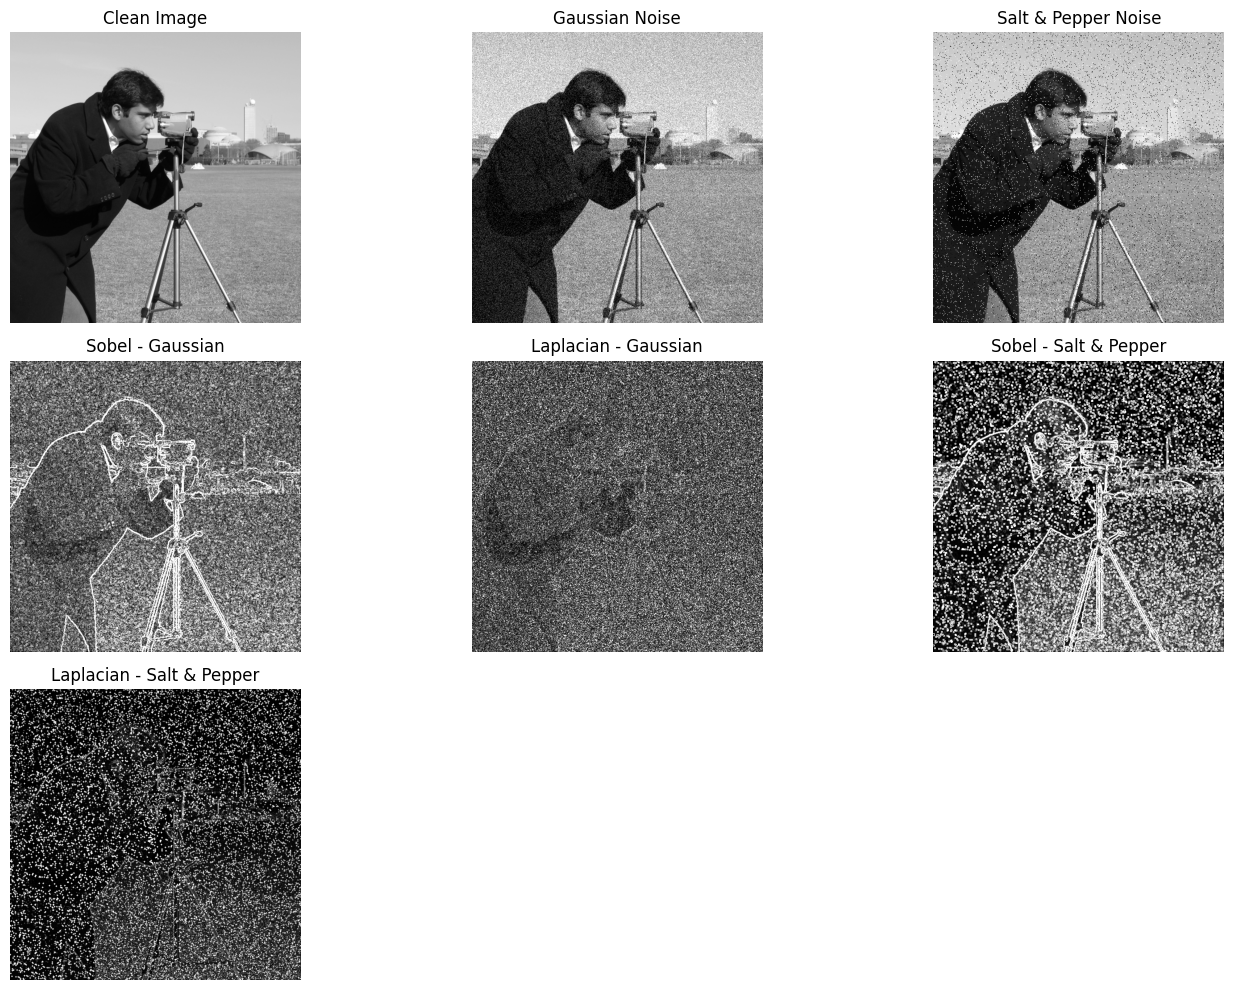

In [4]:
from skimage import data
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load clean grayscale image
clean = data.camera()

# Add Gaussian noise
gaussian_noise = np.random.normal(0, 25, clean.shape)
gaussian = np.clip(clean.astype(float) + gaussian_noise, 0, 255).astype(np.uint8)

# Add Salt and Pepper noise
salt_pepper = clean.copy()

noise = np.random.random(clean.shape)

salt_pepper[noise < 0.03] = 0
salt_pepper[noise > 0.97] = 255

# Function for edge detection
def detect_edges(image):
    sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)

    sobel = cv2.magnitude(sobel_x, sobel_y)
    lap = cv2.Laplacian(image, cv2.CV_64F)

    return cv2.convertScaleAbs(sobel), cv2.convertScaleAbs(lap)

# Apply edge detection
sobel_clean, lap_clean = detect_edges(clean)
sobel_gaussian, lap_gaussian = detect_edges(gaussian)
sobel_sp, lap_sp = detect_edges(salt_pepper)

# Display results
images = [
    clean, gaussian, salt_pepper,
    sobel_gaussian, lap_gaussian,
    sobel_sp, lap_sp
]

titles = [
    "Clean Image", "Gaussian Noise", "Salt & Pepper Noise",
    "Sobel - Gaussian", "Laplacian - Gaussian",
    "Sobel - Salt & Pepper", "Laplacian - Salt & Pepper"
]

plt.figure(figsize=(14, 10))

for i in range(7):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

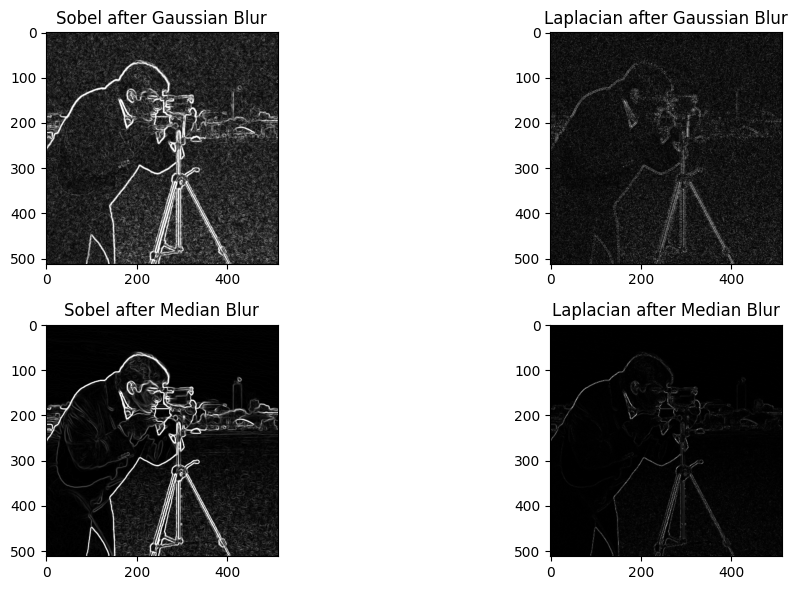

In [5]:
# Gaussian noise removal
gaussian_filtered = cv2.GaussianBlur(gaussian, (5, 5), 0)

# Salt and Pepper noise removal
sp_filtered = cv2.medianBlur(salt_pepper, 5)

# Detect edges after filtering
sobel_g, lap_g = detect_edges(gaussian_filtered)
sobel_s, lap_s = detect_edges(sp_filtered)

# Display improved results
plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.imshow(sobel_g, cmap='gray')
plt.title("Sobel after Gaussian Blur")

plt.subplot(2, 2, 2)
plt.imshow(lap_g, cmap='gray')
plt.title("Laplacian after Gaussian Blur")

plt.subplot(2, 2, 3)
plt.imshow(sobel_s, cmap='gray')
plt.title("Sobel after Median Blur")

plt.subplot(2, 2, 4)
plt.imshow(lap_s, cmap='gray')
plt.title("Laplacian after Median Blur")

plt.tight_layout()
plt.show()

Problem 3: Compression Ratio Comparison (RLE vs Huffman)

Original Image Bits: 586752

RLE Compression
Runs: 55738
Compressed Bits: 2229520
Reduction: -279.98 %

Huffman Compression
Compressed Bits: 549098
Reduction: 6.42 %


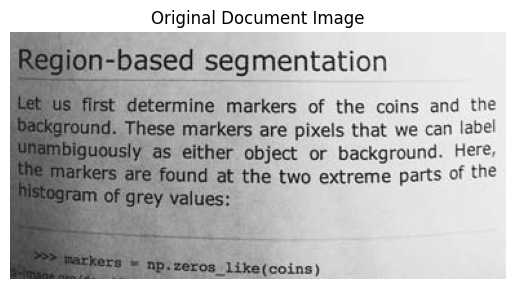

In [6]:
from skimage import data
import numpy as np
import heapq
from collections import Counter
import matplotlib.pyplot as plt

# Load grayscale document image
image = data.page()

# Calculate original bit length
original_bits = image.size * 8

# ---------------- RLE COMPRESSION ----------------

def rle_compress(image):
    pixels = image.flatten()

    runs = []
    count = 1

    for i in range(1, len(pixels)):
        if pixels[i] == pixels[i-1]:
            count += 1
        else:
            runs.append((pixels[i-1], count))
            count = 1

    runs.append((pixels[-1], count))

    return runs

rle_data = rle_compress(image)

# Each run stores 8-bit pixel value + 32-bit run length
rle_bits = len(rle_data) * 40

# ---------------- HUFFMAN COMPRESSION ----------------

def huffman_compress(image):
    pixels = image.flatten()

    frequency = Counter(pixels)

    heap = [[freq, [value, ""]] for value, freq in frequency.items()]
    heapq.heapify(heap)

    if len(heap) == 1:
        return frequency, 0

    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)

        for item in left[1:]:
            item[1] = '0' + item[1]

        for item in right[1:]:
            item[1] = '1' + item[1]

        heapq.heappush(
            heap,
            [left[0] + right[0]] + left[1:] + right[1:]
        )

    codes = heap[0][1:]

    code_dict = {value: code for value, code in codes}

    compressed_bits = sum(
        frequency[value] * len(code_dict[value])
        for value in frequency
    )

    return frequency, compressed_bits

frequency, huffman_bits = huffman_compress(image)

# Calculate compression percentages
rle_reduction = (1 - rle_bits / original_bits) * 100
huffman_reduction = (1 - huffman_bits / original_bits) * 100

# Display results
print("Original Image Bits:", original_bits)

print("\nRLE Compression")
print("Runs:", len(rle_data))
print("Compressed Bits:", rle_bits)
print("Reduction:", round(rle_reduction, 2), "%")

print("\nHuffman Compression")
print("Compressed Bits:", huffman_bits)
print("Reduction:", round(huffman_reduction, 2), "%")

# Display image
plt.imshow(image, cmap='gray')
plt.title("Original Document Image")
plt.axis('off')
plt.show()

Problem 4: JPEG Block Artifact Analysis

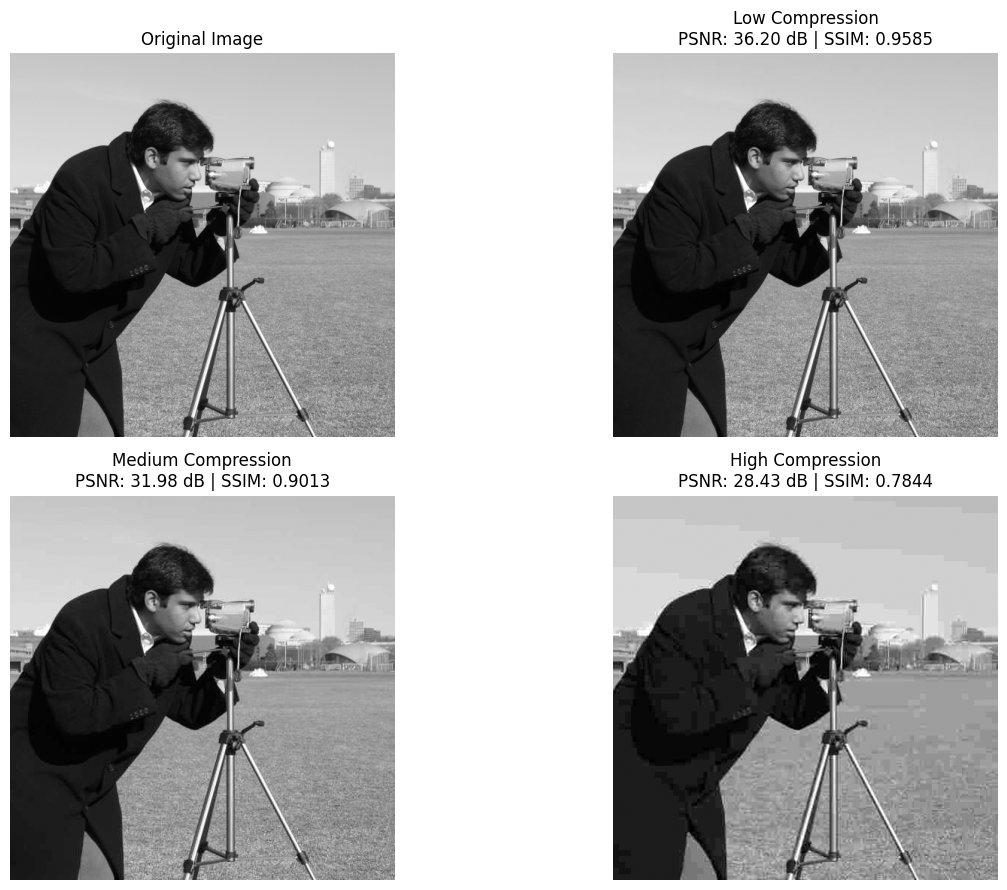

JPEG Compression Comparison

 Low Compression
PSNR: 36.2 dB
SSIM: 0.9585

 Medium Compression
PSNR: 31.98 dB
SSIM: 0.9013

 High Compression
PSNR: 28.43 dB
SSIM: 0.7844


In [7]:
from skimage import data
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

# Load grayscale image
image = data.camera().astype(np.float32)

# Standard JPEG quantization matrix
Q = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float32)


# JPEG-style compression function
def jpeg_compress(image, quality):

    if quality < 50:
        scale = 5000 / quality
    else:
        scale = 200 - 2 * quality

    quant_matrix = np.floor((Q * scale + 50) / 100)
    quant_matrix = np.clip(quant_matrix, 1, 255)

    h, w = image.shape

    compressed = np.zeros((h, w), dtype=np.float32)

    for i in range(0, h, 8):
        for j in range(0, w, 8):

            block = image[i:i+8, j:j+8] - 128

            # Apply DCT
            dct_block = cv2.dct(block)

            # Quantization
            quantized = np.round(dct_block / quant_matrix)

            # Dequantization
            restored = quantized * quant_matrix

            # Apply inverse DCT
            reconstructed = cv2.idct(restored) + 128

            compressed[i:i+8, j:j+8] = reconstructed

    return np.clip(compressed, 0, 255)


# Different compression levels
levels = {
    "Low Compression": 80,
    "Medium Compression": 40,
    "High Compression": 10
}

results = {}

for name, quality in levels.items():

    restored = jpeg_compress(image, quality)

    psnr = peak_signal_noise_ratio(
        image, restored, data_range=255
    )

    ssim = structural_similarity(
        image, restored, data_range=255
    )

    results[name] = (restored, psnr, ssim)


# Display results
plt.figure(figsize=(14, 9))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

for i, (name, result) in enumerate(results.items()):

    restored, psnr, ssim = result

    plt.subplot(2, 2, i+2)
    plt.imshow(restored, cmap='gray')
    plt.title(
        f"{name}\nPSNR: {psnr:.2f} dB | SSIM: {ssim:.4f}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()


# Print numerical comparison
print("JPEG Compression Comparison")

for name, result in results.items():
    restored, psnr, ssim = result

    print("\n", name)
    print("PSNR:", round(psnr, 2), "dB")
    print("SSIM:", round(ssim, 4))

Problem 5: Texture-Based Segmentation Using GLCM Features

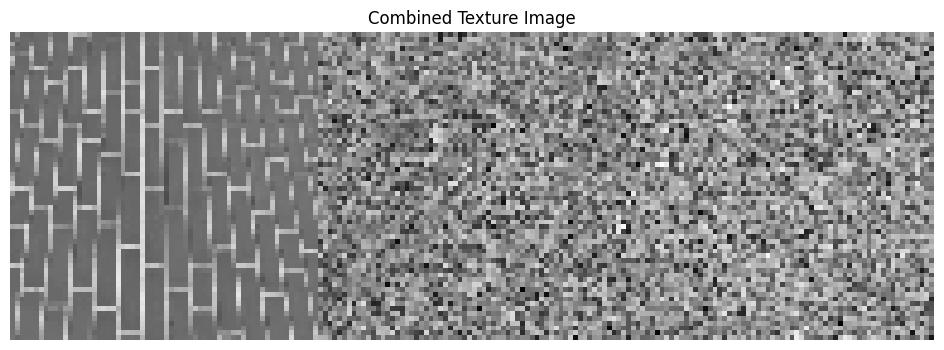

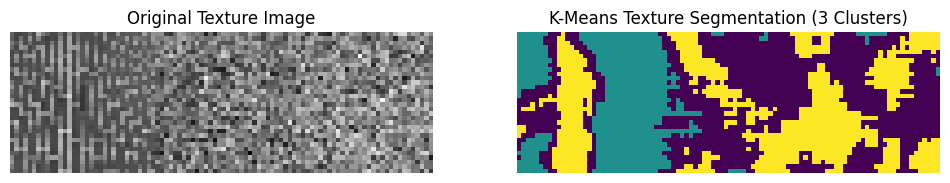

In [8]:
from skimage import data
from skimage.feature import graycomatrix, graycoprops
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load three different textures
brick = data.brick()
grass = data.grass()
gravel = data.gravel()

# Resize all textures
brick = cv2.resize(brick, (64, 64))
grass = cv2.resize(grass, (64, 64))
gravel = cv2.resize(gravel, (64, 64))

# Combine textures into one image
image = np.hstack((brick, grass, gravel))

# Display original texture image
plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title("Combined Texture Image")
plt.axis('off')
plt.show()


# Resize for faster feature extraction
small = cv2.resize(image, (96, 32))

# Reduce gray levels to 8
quantized = (small // 32).astype(np.uint8)

# Extract GLCM features
features = np.zeros((32, 96, 3), dtype=np.float32)

for i in range(32):
    for j in range(96):

        # Extract local neighbourhood
        x1 = max(0, i-4)
        x2 = min(32, i+5)

        y1 = max(0, j-4)
        y2 = min(96, j+5)

        patch = quantized[x1:x2, y1:y2]

        glcm = graycomatrix(
            patch,
            distances=[1],
            angles=[0],
            levels=8,
            symmetric=True,
            normed=True
        )

        contrast = graycoprops(glcm, 'contrast')[0, 0]
        energy = graycoprops(glcm, 'energy')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]

        features[i, j] = [
            contrast,
            energy,
            homogeneity
        ]


# Prepare features for K-means
X = features.reshape(-1, 3)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X_scaled)

# Reshape segmentation output
segmented = labels.reshape(32, 96)

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(small, cmap='gray')
plt.title("Original Texture Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap='viridis')
plt.title("K-Means Texture Segmentation (3 Clusters)")
plt.axis('off')

plt.show()

Problem 6: Multi-Feature Segmentation for Disease Detection

Plant disease image downloaded successfully!


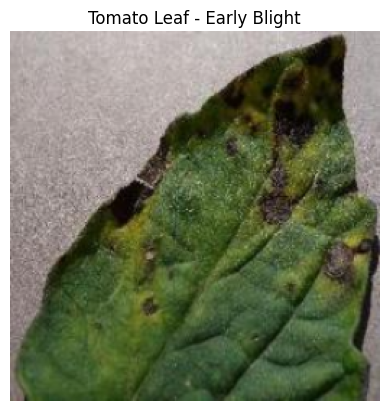

In [9]:
import requests
import cv2
import numpy as np
import matplotlib.pyplot as plt

# GitHub API URL for Early Blight images
url = "https://api.github.com/repos/MAmudha/Tomato-leaf-disease-dataset/contents/Early_blight"

# Get image file list
response = requests.get(url)
response.raise_for_status()

files = response.json()

# Select an image
image_files = [
    f for f in files
    if f["name"].lower().endswith((".jpg", ".jpeg", ".png"))
]

if not image_files:
    raise Exception("No image files found in the dataset folder.")

image_url = image_files[0]["download_url"]

# Download image
image_data = requests.get(image_url)
image_data.raise_for_status()

# Decode image
image = cv2.imdecode(
    np.frombuffer(image_data.content, np.uint8),
    cv2.IMREAD_COLOR
)

# Resize image
image = cv2.resize(image, (256, 256))

print("Plant disease image downloaded successfully!")

# Display image
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Tomato Leaf - Early Blight")
plt.axis('off')
plt.show()

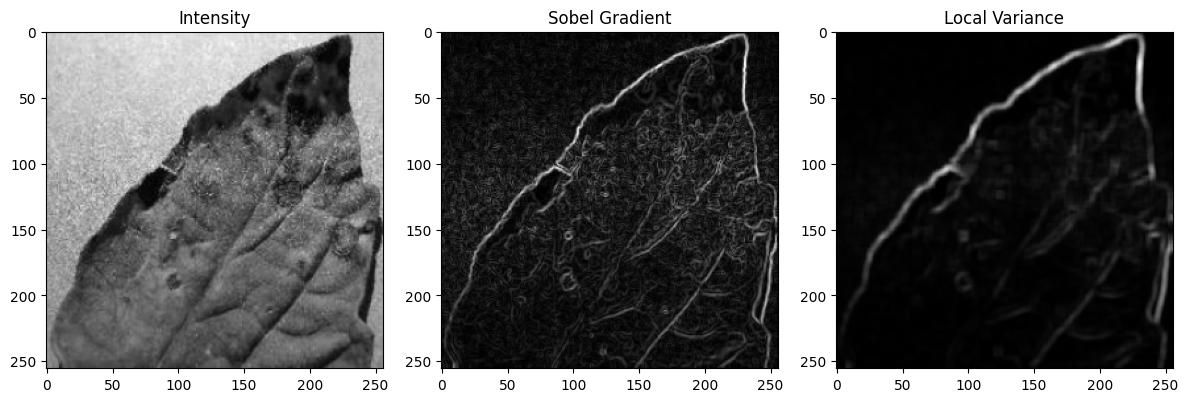

In [10]:
# Convert image into grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Normalize intensity
intensity = gray.astype(np.float32) / 255.0

# Calculate Sobel gradients
sobel_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

# Calculate gradient magnitude
gradient = cv2.magnitude(sobel_x, sobel_y)

# Normalize gradient
gradient = gradient / (gradient.max() + 1e-8)

# Calculate local texture variance
mean = cv2.blur(intensity, (7, 7))
mean_sq = cv2.blur(intensity ** 2, (7, 7))

variance = np.maximum(mean_sq - mean ** 2, 0)

# Normalize variance
variance = variance / (variance.max() + 1e-8)

# Display extracted features
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(intensity, cmap='gray')
plt.title("Intensity")

plt.subplot(1, 3, 2)
plt.imshow(gradient, cmap='gray')
plt.title("Sobel Gradient")

plt.subplot(1, 3, 3)
plt.imshow(variance, cmap='gray')
plt.title("Local Variance")

plt.tight_layout()
plt.show()

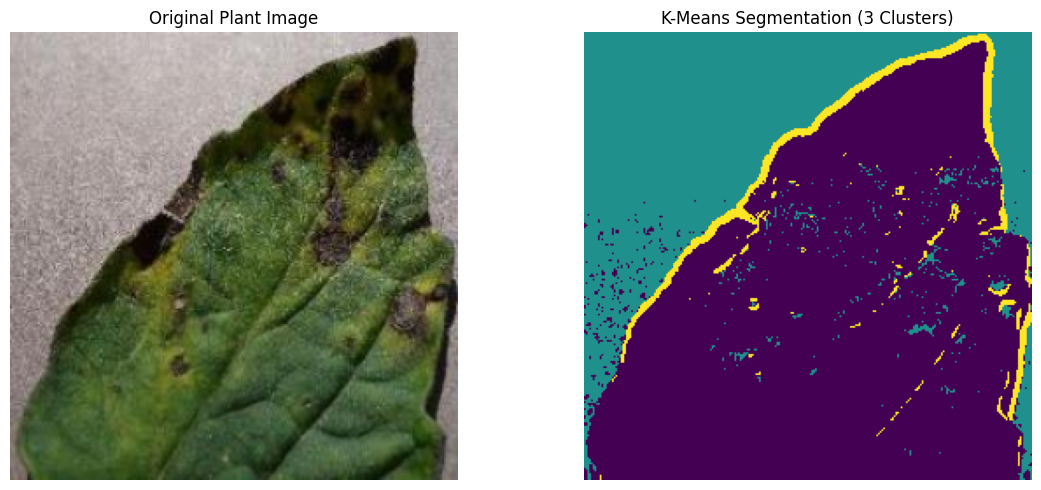

In [11]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Combine extracted features
features = np.stack(
    [intensity, gradient, variance],
    axis=-1
)

# Reshape features
X = features.reshape(-1, 3)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X_scaled)

# Reshape segmentation
segmented = labels.reshape(256, 256)

# Display segmentation
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Plant Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap='viridis')
plt.title("K-Means Segmentation (3 Clusters)")
plt.axis('off')

plt.tight_layout()
plt.show()

In [12]:
# Calculate average features for each cluster
for i in range(3):

    cluster_pixels = X_scaled[labels == i]

    avg_features = cluster_pixels.mean(axis=0)

    print("\nCluster:", i)

    print("Average Intensity:", round(avg_features[0], 3))
    print("Average Gradient:", round(avg_features[1], 3))
    print("Average Variance:", round(avg_features[2], 3))


Cluster: 0
Average Intensity: -0.623
Average Gradient: -0.021
Average Variance: -0.088

Cluster: 1
Average Intensity: 1.236
Average Gradient: -0.326
Average Variance: -0.29

Cluster: 2
Average Intensity: -0.185
Average Gradient: 3.274
Average Variance: 4.112
